# Reprodução das figuras do gfetsim

Este notebook refaz as figuras do relatório. As etapas determinísticas são recalculadas aqui. O Monte Carlo e o Sobol são lidos de `resultados/`, gerados por `python exemplos/gerar_resultados.py`, porque levam dezenas de minutos.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display
from gfetsim import carregar, figuras
from gfetsim.implantacao import modulo as implantacao
from gfetsim.recozimento import modulo as recozimento, silicio
from gfetsim.oxidacao import modulo as oxidacao
from gfetsim.cadeia import mapa_espessura
from gfetsim.eletrico import modulo as eletrico
from gfetsim.calibracao import ajuste
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FIG = RAIZ / 'resultados' / 'notebook'
FIG.mkdir(parents=True, exist_ok=True)
p = carregar(aceitar_provisorios=True)

## 1 Implantação

RustBCA com 1e5 íons (resultado em cache), ajuste de Pearson aos momentos e camada amorfa pelo limiar medido a 300 K (A2).

Momentos(media=40.111799058207964, desvio=18.36187360958255, assimetria=0.280812439858461, curtose=2.727701168641203) I amorfo (0.25, 35.25) transmissão da máscara 0.0


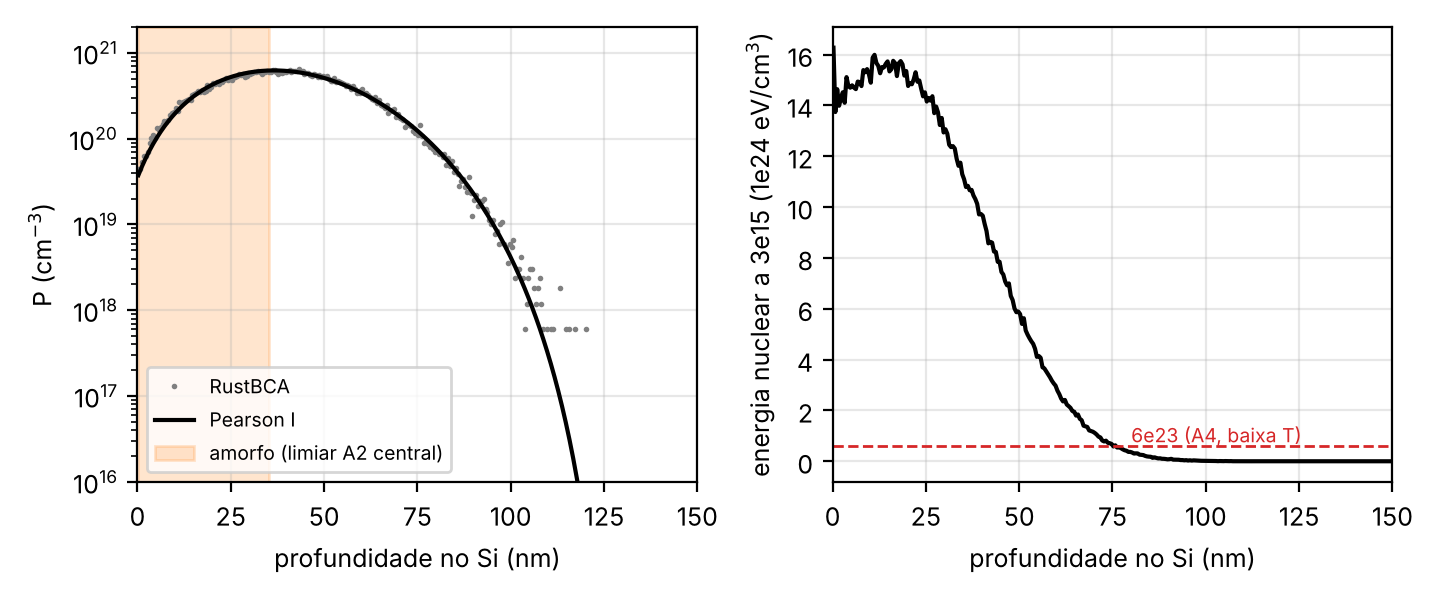

In [2]:
perf = implantacao.simular(p, variante='A_mascara', n_ions=100000)
print(perf.momentos, perf.tipo_pearson, 'amorfo', perf.amorfo_nm, 'transmissão da máscara', perf.transmissao_mascara)
display(Image(figuras.implantacao(perf, FIG / 'fig_implantacao.png')))

## 2 Recozimento

A (RTA) fração ativa 1.0 Rs 39.5 ohm/quadrado
B 850 C fração ativa 1.0 Rs 37.4 ohm/quadrado
B 900 C fração ativa 1.0 Rs 32.7 ohm/quadrado


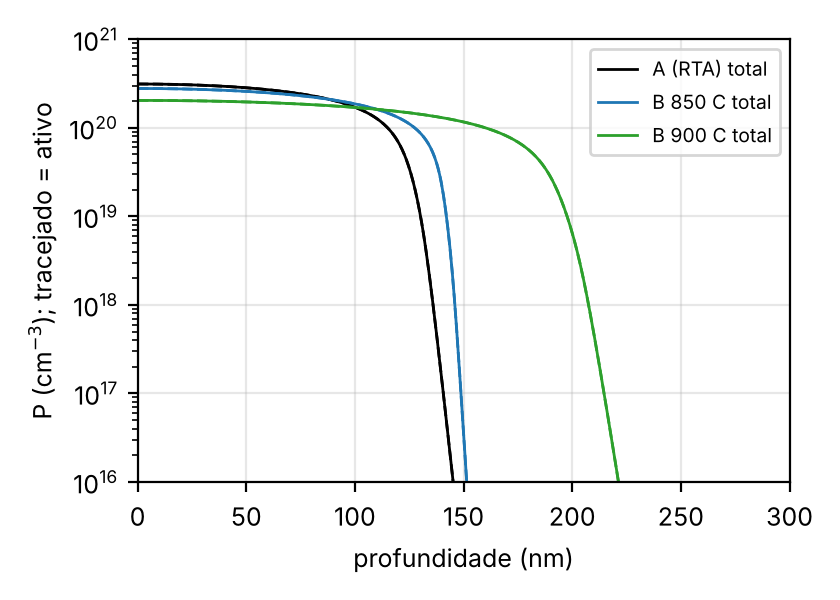

In [3]:
est = {'A (RTA)': recozimento.simular(p, perf, 'A_rta'),
       'B 850 C': recozimento.simular(p, perf, 'B_forno', 850.0),
       'B 900 C': recozimento.simular(p, perf, 'B_forno', 900.0)}
for k, e in est.items():
    print(k, 'fração ativa', round(e.fracao_ativa, 3), 'Rs', round(silicio.resistencia_folha(p, e.x_nm, e.ativo), 1), 'ohm/quadrado')
display(Image(figuras.recozimento(est, FIG / 'fig_recozimento.png')))

## 3 Oxidação de porta

Combinações de temperatura e tempo que dão 20 nm, por ramo de aceleração.

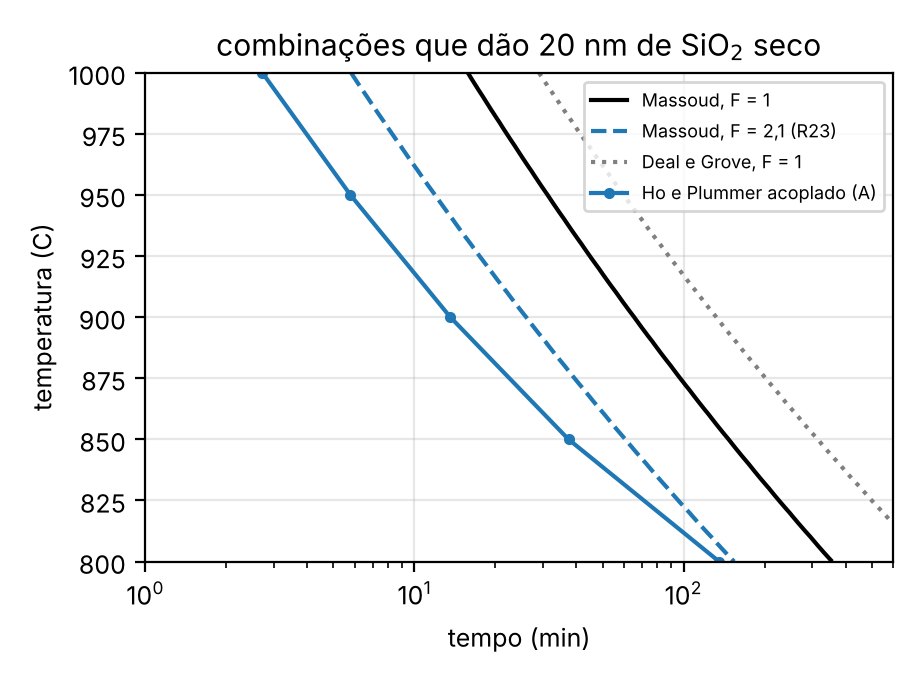

In [4]:
T = np.linspace(800, 1000, 21); t = np.geomspace(1, 600, 120)
mapas = {'Massoud, F = 1': mapa_espessura(p, T, t, 1.0),
         'Massoud, F = 2,1 (R23)': mapa_espessura(p, T, t, 2.1),
         'Deal e Grove, F = 1': mapa_espessura(p, T, t, 1.0, 'deal_grove')}
Ts = [800., 850., 900., 950., 1000.]
ac = {'Ho e Plummer acoplado (A)': (Ts, [oxidacao.tempo_para_alvo(p, est['A (RTA)'], TT, 20.0)[0] for TT in Ts])}
display(Image(figuras.mapa_oxido(T, t, mapas, ac, FIG / 'fig_mapa_oxido.png')))

## 4 Elétrico

C-V da pilha grafeno/SiO2/Si n+ para o perfil simulado e para dopagens uniformes, comparada ao cálculo anterior por depleção.

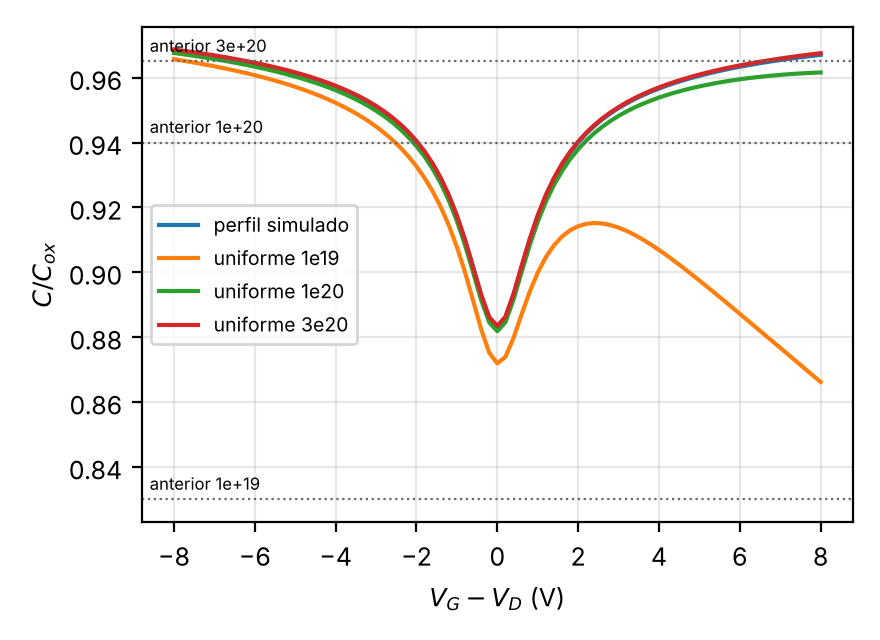

In [5]:
ox = oxidacao.tempo_para_alvo(p, est['A (RTA)'], 900.0, 20.0)[1]
x = ox.estado.x_nm
V = np.linspace(-8, 8, 81)
curvas = {}
for nome, Nd in {'perfil simulado': ox.estado.ativo, 'uniforme 1e19': np.full_like(x, 1e19),
                 'uniforme 1e20': np.full_like(x, 1e20), 'uniforme 3e20': np.full_like(x, 3e20)}.items():
    el = eletrico.simular(p, x, Nd, 20.0, None, 0.0, 0.0, V=V)
    curvas[nome] = (el.V - el.V_D, el.C_F_cm2 / el.C_ox_F_cm2)
display(Image(figuras.cv(curvas, FIG / 'fig_cv.png', {1e19: 0.17, 1e20: 0.06, 3e20: 0.035})))

## 5 Monte Carlo e Sobol (lidos de resultados/)

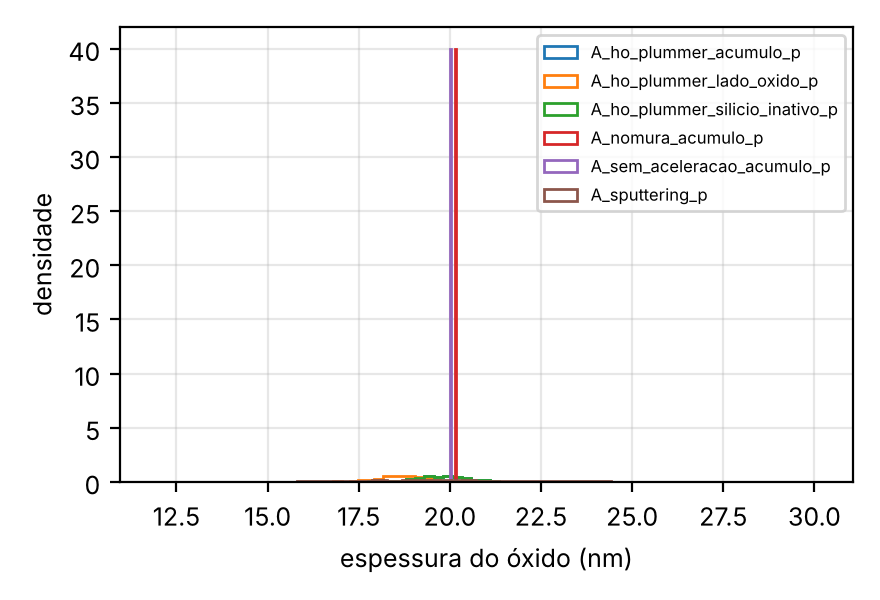

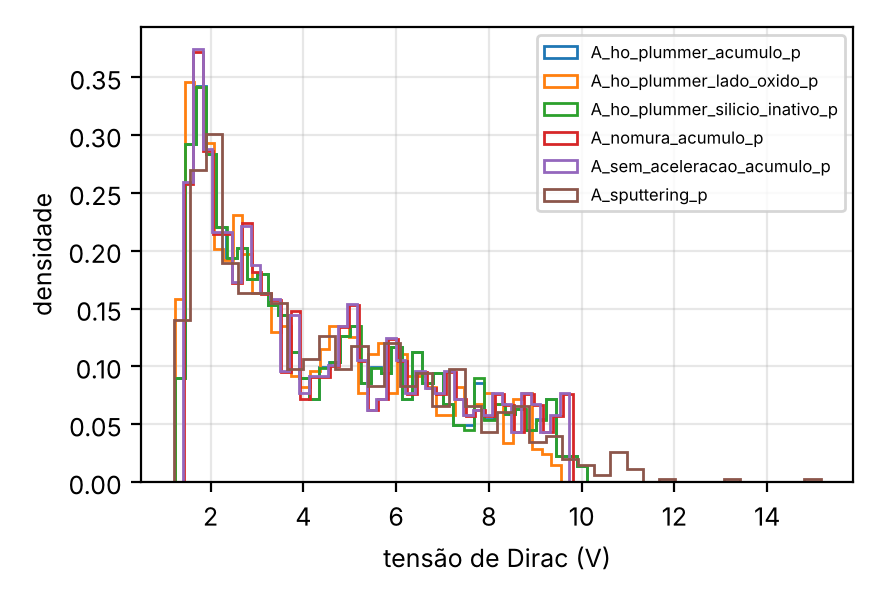

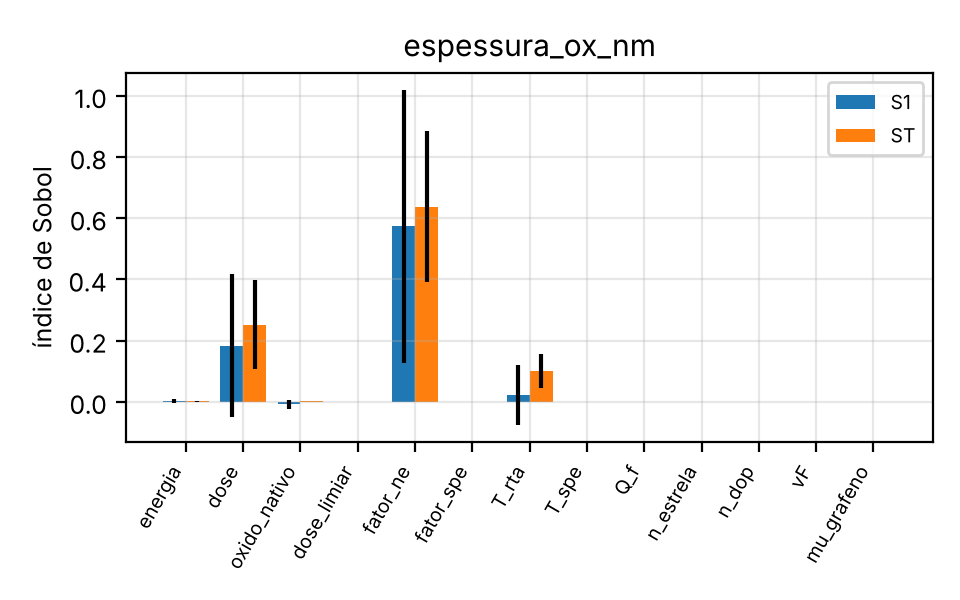

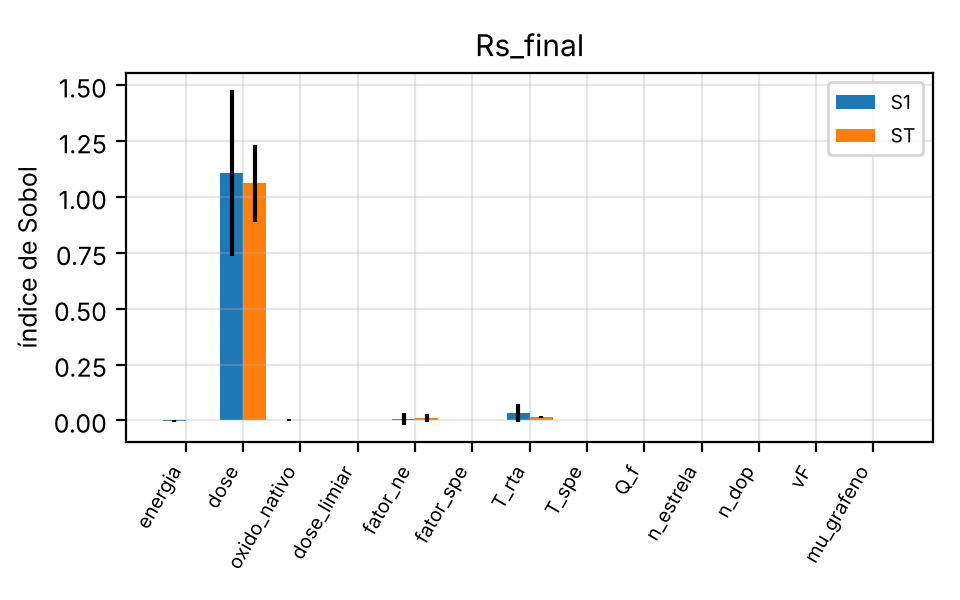

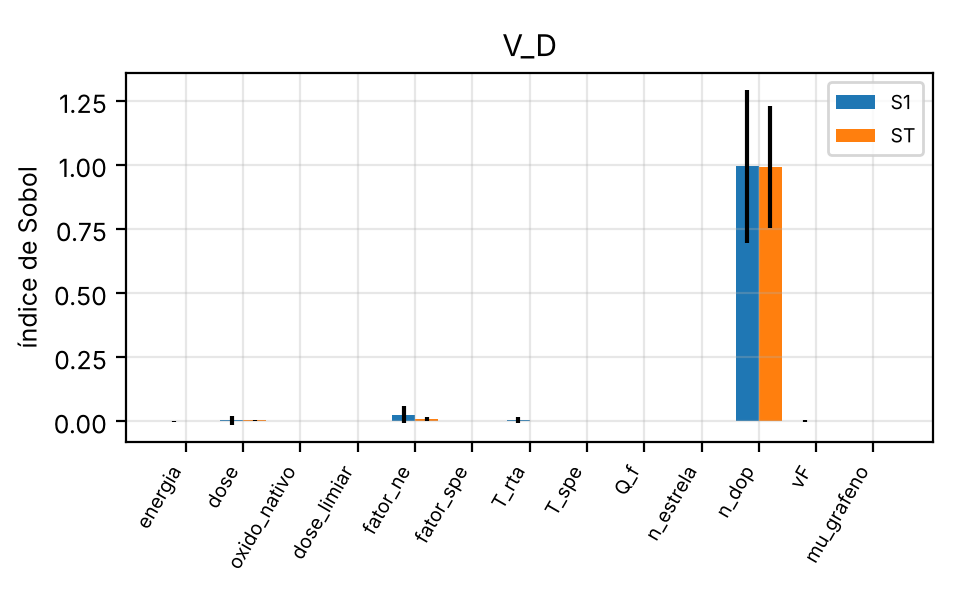

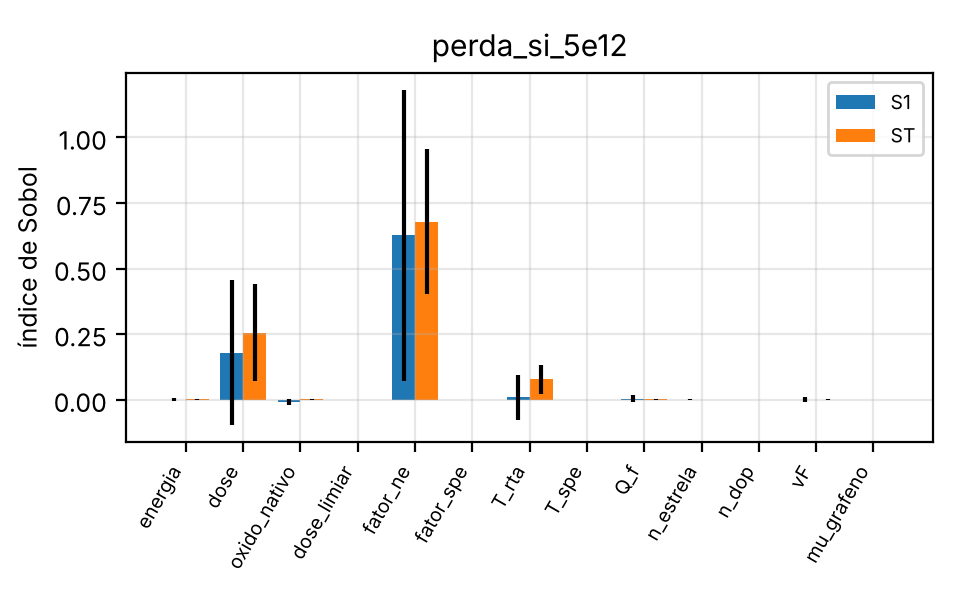

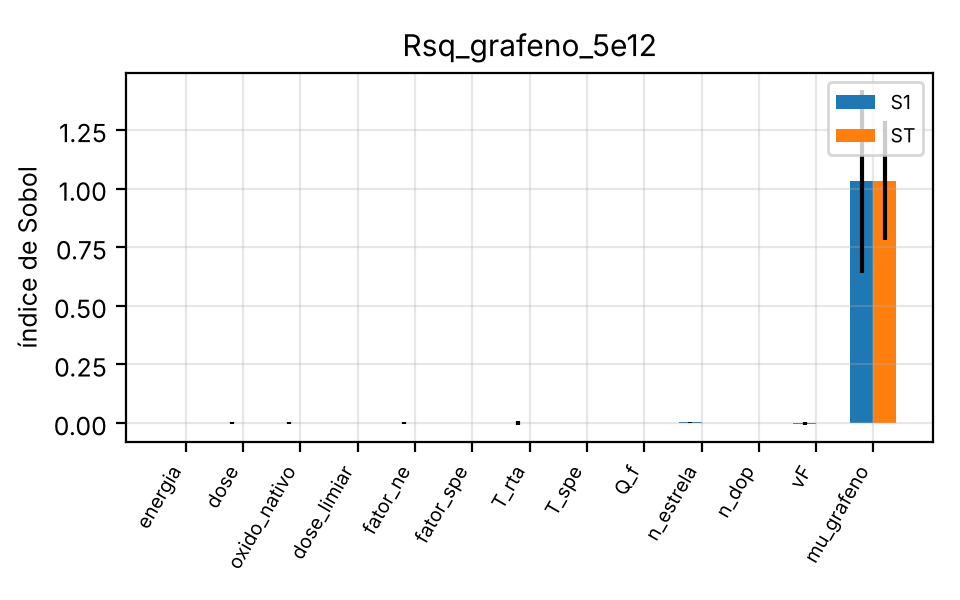

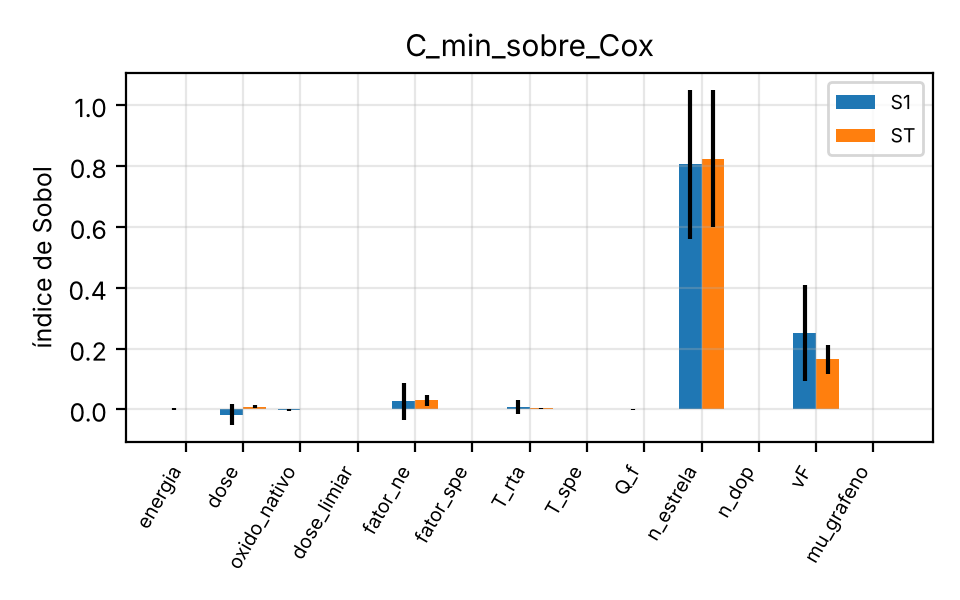

In [6]:
res = {}
for f in sorted((RAIZ / 'resultados').glob('mc_*.npz')):
    d = np.load(f)
    res[f.stem[3:]] = {'saidas': {k[2:]: d[k] for k in d.files if k.startswith('s_')}}
sel = {k: v for k, v in res.items() if k.startswith('A_') and k.endswith('_p')}
if sel:
    display(Image(figuras.histogramas(sel, 'espessura_ox_nm', FIG / 'fig_mc_espessura.png', 'espessura do óxido (nm)')))
    display(Image(figuras.histogramas(sel, 'V_D', FIG / 'fig_mc_VD.png', 'tensão de Dirac (V)')))
resumo = json.loads((RAIZ / 'resultados' / 'resumo.json').read_text()) if (RAIZ / 'resultados' / 'resumo.json').exists() else {}
for s, v in resumo.get('sobol', {}).items():
    v = {k: np.array(w) if k != 'nomes' else w for k, w in v.items()}
    display(Image(figuras.sobol(v, FIG / f'fig_sobol_{s}.png', s)))

## 6 Calibração com os dados do artigo

{
 "inclinacao": 0.08803235515425133,
 "ic95": [
  0.07176153985782224,
  0.10430317045068041
 ],
 "r2": 0.9963230175471663,
 "p": 0.0018401843656666431,
 "intercepto": -0.5124793077501888,
 "p_intercepto": 0.18834544138964274,
 "tempo_20nm_30W": {
  "tempo": 9.396326665523649,
  "ic95": [
   7.080222246139558,
   13.964407159623681
  ],
  "ip95": [
   6.188058058580223,
   19.51312865803548
  ]
 },
 "tempo_20nm_40W": {
  "tempo": 6.647135392244759,
  "ic95": [
   5.578004782341391,
   8.22328403694695
  ],
  "ip95": [
   4.949169056744226,
   10.118654424201106
  ]
 },
 "tempo_20nm_50W": {
  "tempo": 5.142527132247882,
  "ic95": [
   4.574406884497492,
   5.871774451108707
  ],
  "ip95": [
   4.10496940729543,
   6.881996530032087
  ]
 }
}


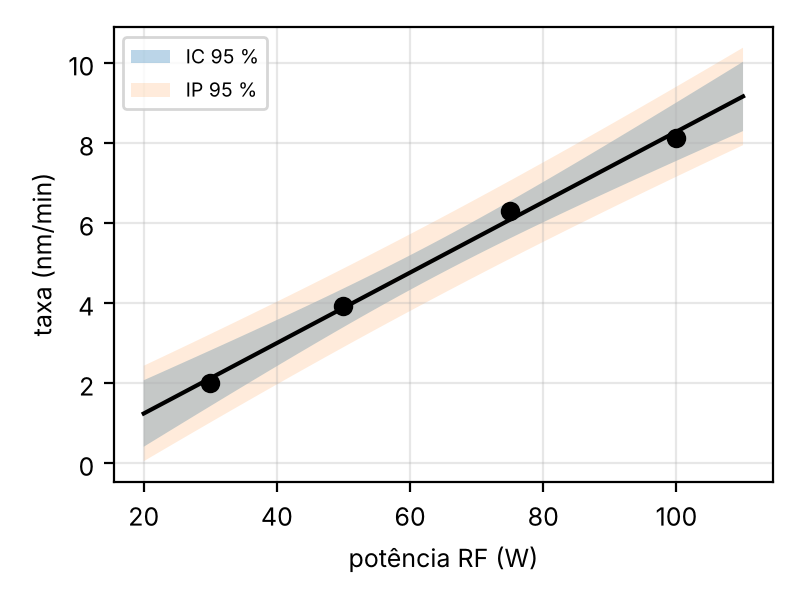

In [7]:
d, _ = ajuste.ler_csv(RAIZ / 'dados' / 'sputtering_calibracao.csv')
r = ajuste.calibrar_sputtering(d)
print(json.dumps(r, indent=1, default=float))
taxa = d['espessura_nm'] / d['tempo_min']; pots = np.unique(d['potencia_W'])
medias = np.array([taxa[d['potencia_W'] == pw].mean() for pw in pots])
display(Image(figuras.sputtering(pots, medias, ajuste.regressao_linear(pots, medias), FIG / 'fig_sputtering.png')))